### COURSE NAME: DATA MINING, MODELLING AND ANALYTICS
### COURSE CODE: DSC8307

### NAME: DDAMULIRA DAVIS KUTESA ACCESS NUMBER: B34974 REGISTRATION NUMBER: S25M19/004

**Data:** Olist Brazilian E-commerce Public Dataset (Kaggle). The nine CSV files are in a `data/` folder next to this notebook.

**Contents**
1. Setup and data loading
2. Data exploration and preparation
3. Product categories purchased together
4. Seller segmentation
5. Unusual orders
6. Late-delivery and delivery-time prediction

## 1. Setup and data loading the data


In [1]:
import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
os.environ["PYTHONWARNINGS"] = "ignore"  # also silences warnings in parallel worker processes
pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42  # fixed seed so results are reproducible
DATA_DIR = Path("data")

In [2]:
files = {
    "customers": "olist_customers_dataset.csv",
    "geolocation": "olist_geolocation_dataset.csv",
    "items": "olist_order_items_dataset.csv",
    "payments": "olist_order_payments_dataset.csv",
    "reviews": "olist_order_reviews_dataset.csv",
    "orders": "olist_orders_dataset.csv",
    "products": "olist_products_dataset.csv",
    "sellers": "olist_sellers_dataset.csv",
    "translation": "product_category_name_translation.csv",
}
dfs = {name: pd.read_csv(DATA_DIR / f) for name, f in files.items()}

# Overview of every table: size, missing values, duplicates
overview = pd.DataFrame({
    name: {
        "rows": len(df),
        "columns": df.shape[1],
        "missing_cells": int(df.isna().sum().sum()),
        "duplicate_rows": int(df.duplicated().sum()),
    }
    for name, df in dfs.items()
}).T
overview

,rows,columns,missing_cells,duplicate_rows
customers,99441,5,0,0
geolocation,1000163,5,0,261831
items,112650,7,0,0
payments,103886,5,0,0
reviews,99224,7,145903,0
orders,99441,8,4908,0
products,32951,9,2448,0
sellers,3095,4,0,0
translation,71,2,0,0


In [3]:
# Parse all timestamp columns in the orders table
orders = dfs["orders"].copy()
date_cols = ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
             "order_delivered_customer_date", "order_estimated_delivery_date"]
for c in date_cols:
    orders[c] = pd.to_datetime(orders[c])
orders[date_cols].describe()

,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
count,99441,99281,97658,96476,99441
mean,2017-12-31 08:43:12.776581,2017-12-31 18:35:24.098800,2018-01-04 21:49:48.138278,2018-01-14 12:09:19.035542,2018-01-24 03:08:37.730111
min,2016-09-04 21:15:19,2016-09-15 12:16:38,2016-10-08 10:34:01,2016-10-11 13:46:32,2016-09-30 00:00:00
25%,2017-09-12 14:46:19,2017-09-12 23:24:16,2017-09-15 22:28:50.250000,2017-09-25 22:07:22.250000,2017-10-03 00:00:00
50%,2018-01-18 23:04:36,2018-01-19 11:36:13,2018-01-24 16:10:58,2018-02-02 19:28:10.500000,2018-02-15 00:00:00
75%,2018-05-04 15:42:16,2018-05-04 20:35:10,2018-05-08 13:37:45,2018-05-15 22:48:52.250000,2018-05-25 00:00:00
max,2018-10-17 17:30:18,2018-09-03 17:40:06,2018-09-11 19:48:28,2018-10-17 13:22:46,2018-11-12 00:00:00


In [4]:
# Order status distribution: only 'delivered' orders have a full delivery history
orders["order_status"].value_counts(normalize=True).round(4)

order_status
delivered      0.9702
shipped        0.0111
canceled       0.0063
unavailable    0.0061
invoiced       0.0032
processing     0.0030
created        0.0001
approved       0.0000
Name: proportion, dtype: float64

## 2. Data exploration and preparation

The dataset is relational: the `orders` table is the hub, linked to `items`, `payments` and `reviews` by `order_id`, to `customers` by `customer_id`, and through `items` to `products` and `sellers`. `geolocation` links to customers and sellers through the zip-code prefix. Each table is cleaned separately before being aggregated to two levels of analysis: one row per order (Tasks 4 and 5) and one row per order item (Tasks 2 and 3).

### 2.1 Data quality checks

In [5]:
# Missing values per column, for columns that have any
missing = {name: df.isna().sum()[lambda s: s > 0] for name, df in dfs.items()}
for name, s in missing.items():
    if len(s):
        print(f"--- {name} ---")
        print(s.to_string(), "\n")

--- reviews ---
review_comment_title      87656
review_comment_message    58247 

--- orders ---
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965 

--- products ---
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2 



In [6]:
# Logical consistency checks on the order timeline
checks = {
    "delivered status but no delivery date": ((orders.order_status == "delivered") & orders.order_delivered_customer_date.isna()).sum(),
    "delivery date but status not delivered": ((orders.order_status != "delivered") & orders.order_delivered_customer_date.notna()).sum(),
    "approved before purchase": (orders.order_approved_at < orders.order_purchase_timestamp).sum(),
    "delivered to customer before carrier pickup": (orders.order_delivered_customer_date < orders.order_delivered_carrier_date).sum(),
    "carrier pickup before purchase": (orders.order_delivered_carrier_date < orders.order_purchase_timestamp).sum(),
}
pd.Series(checks, name="count")

delivered status but no delivery date            8
delivery date but status not delivered           6
approved before purchase                         0
delivered to customer before carrier pickup     23
carrier pickup before purchase                 166
Name: count, dtype: int64

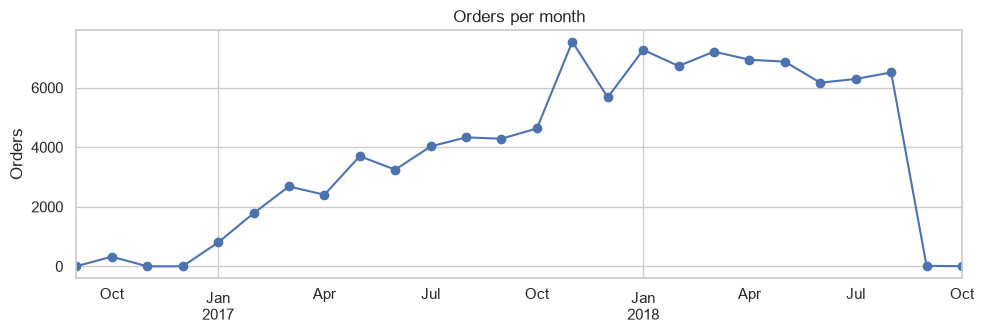

(order_purchase_timestamp
 2016-09-01      4
 2016-10-01    324
 2016-11-01      0
 2016-12-01      1
 Freq: MS, dtype: int64,
 order_purchase_timestamp
 2018-07-01    6292
 2018-08-01    6512
 2018-09-01      16
 2018-10-01       4
 Freq: MS, dtype: int64)

In [7]:
# Orders per month: shows the time span and the sparse first/last months
monthly = orders.set_index("order_purchase_timestamp").resample("MS").size()
ax = monthly.plot(figsize=(10, 3.5), marker="o")
ax.set_title("Orders per month"); ax.set_xlabel(""); ax.set_ylabel("Orders")
plt.tight_layout(); plt.show()
monthly.head(4), monthly.tail(4)

### 2.2 Cleaning each table

In [8]:
# Products: translate category names to English; missing categories labelled 'unknown';
# missing physical dimensions imputed with the median (robust to skewed sizes)
products = dfs["products"].merge(dfs["translation"], on="product_category_name", how="left")
products["category"] = (products["product_category_name_english"]
                        .fillna(products["product_category_name"])   # categories absent from translation file
                        .fillna("unknown"))
dim_cols = ["product_weight_g", "product_length_cm", "product_height_cm", "product_width_cm"]
products[dim_cols] = products[dim_cols].fillna(products[dim_cols].median())
products["product_volume_cm3"] = products.product_length_cm * products.product_height_cm * products.product_width_cm
print("Categories:", products.category.nunique(), "| unknown:", (products.category == "unknown").sum())

Categories: 74 | unknown: 610


In [9]:
# Reviews: some orders carry more than one review; the most recent answer is kept
reviews = dfs["reviews"].copy()
reviews["review_answer_timestamp"] = pd.to_datetime(reviews["review_answer_timestamp"])
print("Orders with >1 review:", reviews.order_id.duplicated().sum())
reviews = (reviews.sort_values("review_answer_timestamp")
                  .drop_duplicates("order_id", keep="last")[["order_id", "review_score"]])

Orders with >1 review: 551


In [10]:
# Payments: aggregated to one row per order
payments = dfs["payments"]
pay_order = payments.groupby("order_id").agg(
    payment_value=("payment_value", "sum"),
    payment_installments=("payment_installments", "max"),
    n_payment_methods=("payment_type", "nunique"),
    payment_type=("payment_type", lambda s: s.mode().iloc[0]),
).reset_index()

In [11]:
# Geolocation: many coordinates per zip prefix; the median per prefix is used.
# Coordinates outside Brazil's bounding box are removed first as entry errors.
geo = dfs["geolocation"]
in_brazil = geo.geolocation_lat.between(-34, 5.5) & geo.geolocation_lng.between(-74, -34)
print("Geolocation rows outside Brazil removed:", (~in_brazil).sum())
geo = (geo[in_brazil].groupby("geolocation_zip_code_prefix")[["geolocation_lat", "geolocation_lng"]]
       .median().rename(columns={"geolocation_lat": "lat", "geolocation_lng": "lng"}))

def haversine_km(lat1, lng1, lat2, lng2):
    """Great-circle distance in kilometres."""
    lat1, lng1, lat2, lng2 = map(np.radians, [lat1, lng1, lat2, lng2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lng2 - lng1) / 2) ** 2
    return 6371 * 2 * np.arcsin(np.sqrt(a))

Geolocation rows outside Brazil removed: 42


### 2.3 Item-level table (one row per item sold)

In [12]:
customers = dfs["customers"].merge(geo, left_on="customer_zip_code_prefix", right_index=True, how="left")
sellers = dfs["sellers"].merge(geo, left_on="seller_zip_code_prefix", right_index=True, how="left")

items_full = (dfs["items"]
    .merge(products[["product_id", "category", "product_weight_g", "product_volume_cm3", "product_photos_qty"]], on="product_id", how="left")
    .merge(sellers.rename(columns={"lat": "seller_lat", "lng": "seller_lng"}), on="seller_id", how="left")
    .merge(orders, on="order_id", how="left")
    .merge(customers.rename(columns={"lat": "cust_lat", "lng": "cust_lng"}), on="customer_id", how="left"))
items_full["shipping_limit_date"] = pd.to_datetime(items_full["shipping_limit_date"])
items_full["distance_km"] = haversine_km(items_full.seller_lat, items_full.seller_lng,
                                         items_full.cust_lat, items_full.cust_lng)
print(items_full.shape)
print("Items without distance (zip prefix not in geolocation):", items_full.distance_km.isna().sum())

# Join check: left joins on many-to-one keys must not change the number of item rows
assert len(items_full) == len(dfs["items"]), "join inflated item rows"
print("Row check passed: items_full has", len(items_full), "rows =", len(dfs["items"]), "items")

(112650, 30)
Items without distance (zip prefix not in geolocation): 555
Row check passed: items_full has 112650 rows = 112650 items


### 2.4 Order-level table (one row per order)

In [13]:
item_order = items_full.groupby("order_id").agg(
    n_items=("order_item_id", "count"),
    n_sellers=("seller_id", "nunique"),
    n_categories=("category", "nunique"),
    main_category=("category", lambda s: s.mode().iloc[0]),
    total_price=("price", "sum"),
    total_freight=("freight_value", "sum"),
    total_weight_g=("product_weight_g", "sum"),
    total_volume_cm3=("product_volume_cm3", "sum"),
    distance_km=("distance_km", "mean"),
    seller_state=("seller_state", lambda s: s.mode().iloc[0]),
    shipping_limit_date=("shipping_limit_date", "max"),
).reset_index()

order_df = (orders
    .merge(dfs["customers"][["customer_id", "customer_unique_id", "customer_state"]], on="customer_id", how="left")
    .merge(item_order, on="order_id", how="left")
    .merge(pay_order, on="order_id", how="left")
    .merge(reviews, on="order_id", how="left"))

# Derived time features
order_df["delivery_days"] = (order_df.order_delivered_customer_date - order_df.order_purchase_timestamp).dt.total_seconds() / 86400
order_df["estimated_days"] = (order_df.order_estimated_delivery_date - order_df.order_purchase_timestamp).dt.total_seconds() / 86400
order_df["approval_hours"] = (order_df.order_approved_at - order_df.order_purchase_timestamp).dt.total_seconds() / 3600
order_df["delay_days"] = (order_df.order_delivered_customer_date.dt.normalize() - order_df.order_estimated_delivery_date.dt.normalize()).dt.days
order_df["is_late"] = (order_df["delay_days"] > 0).astype("Int64").where(order_df.order_delivered_customer_date.notna())
order_df["freight_ratio"] = order_df.total_freight / order_df.total_price
order_df["same_state"] = (order_df.customer_state == order_df.seller_state).astype(int)
print(order_df.shape)

# Join check: one row per order after all joins
assert len(order_df) == len(orders) and order_df.order_id.is_unique, "join inflated order rows"
print("Row check passed: order_df has one row per order")

(99441, 33)
Row check passed: order_df has one row per order


In [14]:
# Analysis set for delivery questions: delivered orders with a valid, consistent timeline
delivered = order_df[
    (order_df.order_status == "delivered")
    & order_df.order_delivered_customer_date.notna()
    & order_df.n_items.notna()
    & (order_df.delivery_days > 0)
].copy()
print(f"Delivered orders kept: {len(delivered):,} of {len(order_df):,} ({len(delivered)/len(order_df):.1%})")
print(f"Late delivery rate: {delivered.is_late.mean():.2%}")
delivered[["delivery_days", "estimated_days", "delay_days", "total_price", "total_freight", "distance_km"]].describe().round(2)

Delivered orders kept: 96,470 of 99,441 (97.0%)
Late delivery rate: 6.77%


,delivery_days,estimated_days,delay_days,total_price,total_freight,distance_km
count,96470.00,96470.00,96470.00,96470.00,96470.00,95993.00
mean,12.56,23.74,-11.88,137.04,22.79,600.44
std,9.55,8.76,10.18,209.05,21.56,592.17
min,0.53,2.01,-147.00,0.85,0.00,0.00
25%,6.77,18.33,-17.00,45.90,13.85,186.74
50%,10.22,23.23,-12.00,86.50,17.17,433.82
75%,15.72,28.41,-7.00,149.90,24.02,797.34
max,209.63,155.14,188.00,13440.00,1794.96,3398.49


### 2.5 Exploratory views

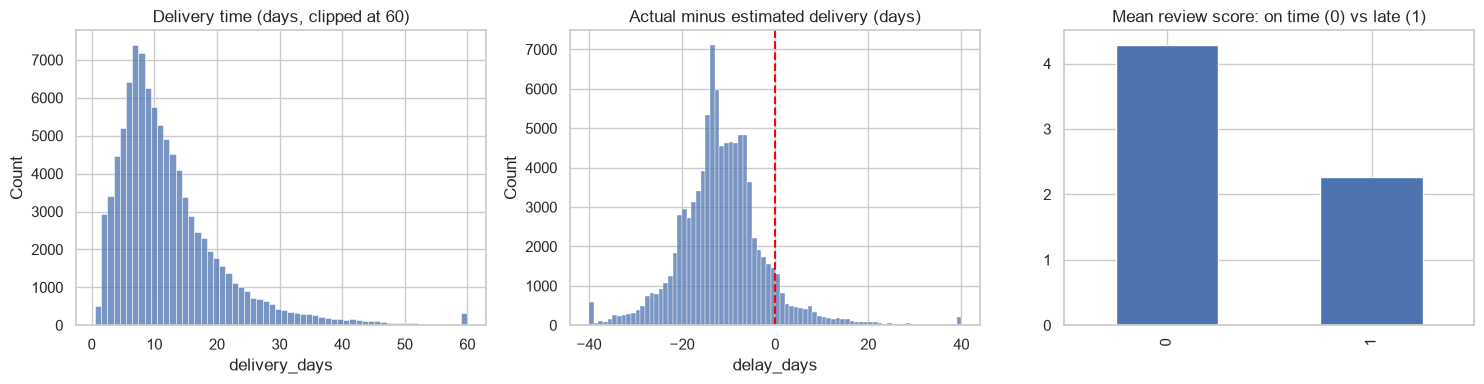

Mean review score by late flag: {np.int64(0): 4.29, np.int64(1): 2.27}


In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(delivered.delivery_days.clip(upper=60), bins=60, ax=axes[0])
axes[0].set_title("Delivery time (days, clipped at 60)")
sns.histplot(delivered.delay_days.clip(-40, 40), bins=80, ax=axes[1])
axes[1].axvline(0, color="red", ls="--"); axes[1].set_title("Actual minus estimated delivery (days)")
delivered.groupby("is_late").review_score.mean().plot.bar(ax=axes[2])
axes[2].set_title("Mean review score: on time (0) vs late (1)"); axes[2].set_xlabel("")
plt.tight_layout(); plt.show()
print("Mean review score by late flag:", delivered.groupby("is_late").review_score.mean().round(2).to_dict())

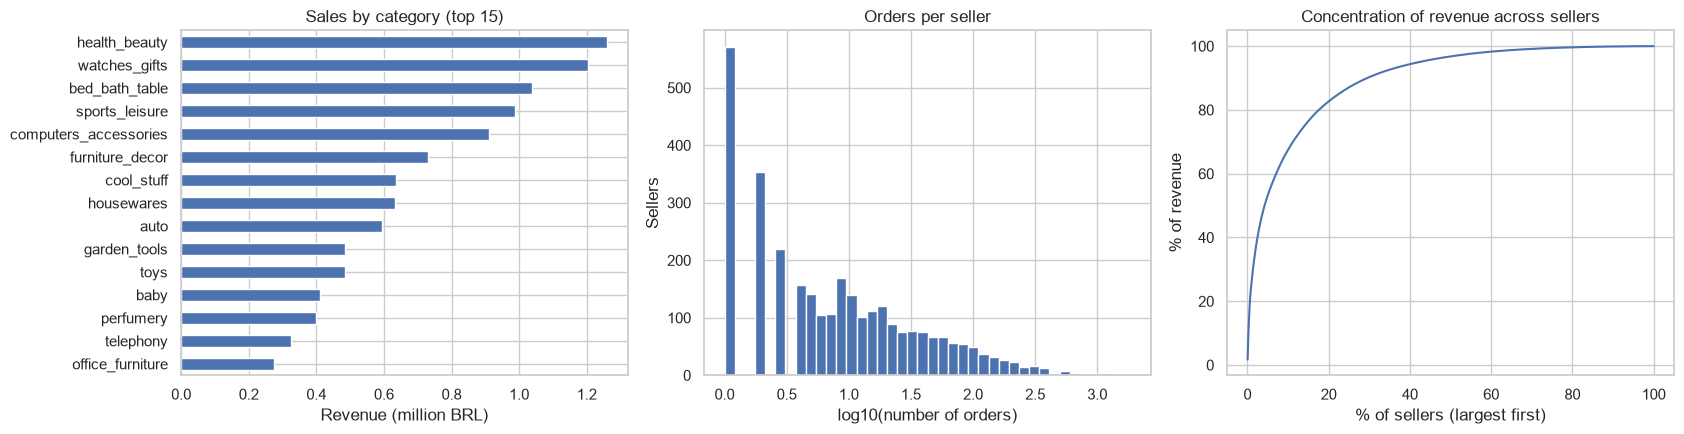

Top 10% of sellers earn 67.5% of revenue
Top 5 categories by revenue (million BRL):
category
health_beauty            1.259
watches_gifts            1.205
bed_bath_table           1.037
sports_leisure           0.988
computers_accessories    0.912


In [16]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
cat_sales = items_full.groupby("category").price.sum().sort_values(ascending=False) / 1e6
cat_sales.head(15)[::-1].plot.barh(ax=axes[0])
axes[0].set_title("Sales by category (top 15)"); axes[0].set_xlabel("Revenue (million BRL)"); axes[0].set_ylabel("")

seller_orders = items_full.groupby("seller_id").order_id.nunique()
axes[1].hist(np.log10(seller_orders), bins=40)
axes[1].set_title("Orders per seller"); axes[1].set_xlabel("log10(number of orders)"); axes[1].set_ylabel("Sellers")

rev = items_full.groupby("seller_id").price.sum().sort_values(ascending=False)
axes[2].plot(np.arange(1, len(rev) + 1) / len(rev) * 100, rev.cumsum() / rev.sum() * 100)
axes[2].set_title("Concentration of revenue across sellers"); axes[2].set_xlabel("% of sellers (largest first)"); axes[2].set_ylabel("% of revenue")
plt.tight_layout(); plt.show()
print(f"Top 10% of sellers earn {rev.head(int(len(rev) * 0.1)).sum() / rev.sum():.1%} of revenue")
print("Top 5 categories by revenue (million BRL):")
print(cat_sales.head(5).round(3).to_string())

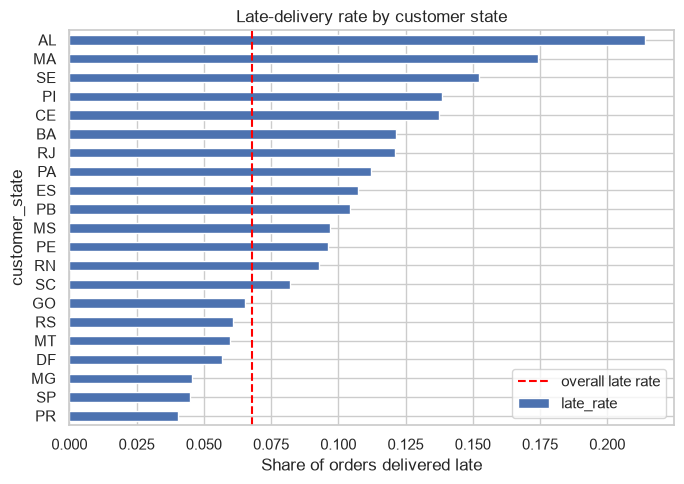

,orders,late_rate,median_days
customer_state,,,
AL,397,0.214,22.333
MA,717,0.174,19.191
SE,335,0.152,18.014
PI,476,0.139,16.292
CE,1279,0.138,18.209
BA,3256,0.122,16.914
RJ,12350,0.121,12.042
PA,946,0.112,21.078
ES,1995,0.107,13.637


In [17]:
# Late rate and delivery time by customer state (states with >= 300 delivered orders)
state = (delivered.groupby("customer_state")
         .agg(orders=("order_id", "count"), late_rate=("is_late", "mean"), median_days=("delivery_days", "median"))
         .query("orders >= 300").sort_values("late_rate", ascending=False))
ax = state.late_rate.sort_values().plot.barh(figsize=(7, 5))
ax.axvline(delivered.is_late.mean(), color="red", ls="--", label="overall late rate")
ax.set_title("Late-delivery rate by customer state"); ax.set_xlabel("Share of orders delivered late"); ax.legend()
plt.tight_layout(); plt.show()
state.round(3)

In [18]:
# Items per order: determines how much co-purchase information exists for Task 2
print(order_df.n_items.value_counts(normalize=True).head(5).round(4))
print("Orders with 2+ distinct categories:", (order_df.n_categories >= 2).sum())
print("Customers (unique) with 2+ orders:", (order_df.groupby("customer_unique_id").order_id.nunique() >= 2).sum())

n_items
1.0    0.9006
2.0    0.0762
3.0    0.0134
4.0    0.0051
5.0    0.0021
Name: proportion, dtype: float64
Orders with 2+ distinct categories: 786
Customers (unique) with 2+ orders: 2997


## 3. Product categories purchased together

Association rule mining [Agrawal & Srikant, 1994] is applied at product-category level with the FP-Growth algorithm [Han et al., 2000], which finds the same frequent itemsets as Apriori without generating candidate sets. Rules are judged on support, confidence and lift. A lift above 1 means two categories occur together more often than independence would predict, so only those rules are kept.

Section 2.5 showed that about 90% of orders contain a single item, so very few orders contain two or more categories. Two basket definitions are therefore compared:
- Order basket: the categories bought in the same order.
- Customer basket: all categories bought by the same customer (`customer_unique_id`) across all their orders, which also captures complementary purchases made on separate occasions.

In [19]:
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import fpgrowth, association_rules

known = items_full[items_full.category != "unknown"]
order_baskets = known.groupby("order_id")["category"].apply(lambda s: sorted(set(s)))
cust_baskets = known.groupby("customer_unique_id")["category"].apply(lambda s: sorted(set(s)))

summary = pd.DataFrame({
    "baskets": [len(order_baskets), len(cust_baskets)],
    "with 2+ categories": [(order_baskets.str.len() >= 2).sum(), (cust_baskets.str.len() >= 2).sum()],
}, index=["order basket", "customer basket"])
summary["share with 2+"] = (summary["with 2+ categories"] / summary["baskets"]).round(4)
summary

,baskets,with 2+ categories,share with 2+
order basket,97277,727,0.0075
customer basket,94108,2212,0.0235


In [20]:
def mine_rules(baskets, min_count=10, min_lift=1.0):
    """FP-Growth on multi-category baskets; support thresholds are set as an absolute count
    so that every rule is backed by at least `min_count` baskets."""
    multi = baskets[baskets.str.len() >= 2].tolist()
    te = TransactionEncoder()
    X = pd.DataFrame(te.fit(multi).transform(multi), columns=te.columns_)
    itemsets = fpgrowth(X, min_support=min_count / len(X), use_colnames=True)
    rules = association_rules(itemsets, num_itemsets=len(X), metric="lift", min_threshold=min_lift)
    rules["count"] = (rules["support"] * len(X)).round().astype(int)
    rules["antecedents"] = rules["antecedents"].apply(lambda s: ", ".join(sorted(s)))
    rules["consequents"] = rules["consequents"].apply(lambda s: ", ".join(sorted(s)))
    cols = ["antecedents", "consequents", "count", "support", "confidence", "lift"]
    return rules[cols].sort_values(["lift", "count"], ascending=False).reset_index(drop=True), len(X)

order_rules, n_order = mine_rules(order_baskets, min_count=10)
cust_rules, n_cust = mine_rules(cust_baskets, min_count=10)
print(f"Order-level: {len(order_rules)} rules from {n_order} multi-category baskets")
print(f"Customer-level: {len(cust_rules)} rules from {n_cust} multi-category baskets")

Order-level: 20 rules from 727 multi-category baskets
Customer-level: 36 rules from 2212 multi-category baskets


In [21]:
print("Order-level rules (lift > 1, at least 10 baskets)")
order_rules.round(3).head(15)

Order-level rules (lift > 1, at least 10 baskets)


,antecedents,consequents,count,support,confidence,lift
0,health_beauty,perfumery,12,0.017,0.171,4.793
1,perfumery,health_beauty,12,0.017,0.462,4.793
2,bed_bath_table,home_confort,43,0.059,0.217,3.158
3,home_confort,bed_bath_table,43,0.059,0.860,3.158
4,toys,baby,19,0.026,0.380,2.971
5,baby,toys,19,0.026,0.204,2.971
6,baby,cool_stuff,20,0.028,0.215,2.369
7,cool_stuff,baby,20,0.028,0.303,2.369
8,furniture_decor,construction_tools_lights,11,0.015,0.054,2.189
9,construction_tools_lights,furniture_decor,11,0.015,0.611,2.189


In [22]:
print("Customer-level rules (lift > 1, at least 10 baskets)")
cust_rules.round(3).head(20)

Customer-level rules (lift > 1, at least 10 baskets)


,antecedents,consequents,count,support,confidence,lift
0,bed_bath_table,home_confort,54,0.024,0.100,3.036
1,home_confort,bed_bath_table,54,0.024,0.740,3.036
2,construction_tools_lights,furniture_decor,18,0.008,0.600,2.577
3,furniture_decor,construction_tools_lights,18,0.008,0.035,2.577
4,baby,cool_stuff,31,0.014,0.179,2.509
5,cool_stuff,baby,31,0.014,0.196,2.509
6,toys,baby,27,0.012,0.156,1.996
7,baby,toys,27,0.012,0.156,1.996
8,home_construction,garden_tools,10,0.005,0.179,1.965
9,garden_tools,home_construction,10,0.005,0.050,1.965


In [23]:
# Sensitivity of the customer-level result to the minimum-count threshold
sens = []
for mc in [5, 10, 20, 40]:
    r, _ = mine_rules(cust_baskets, min_count=mc)
    sens.append({"min_count": mc, "rules": len(r), "rules with lift > 2": (r.lift > 2).sum(),
                 "max lift": r.lift.max() if len(r) else np.nan})
pd.DataFrame(sens).round(2)

,min_count,rules,rules with lift > 2,max lift
0,5,84,18,5.79
1,10,36,6,3.04
2,20,16,4,3.04
3,40,4,2,3.04


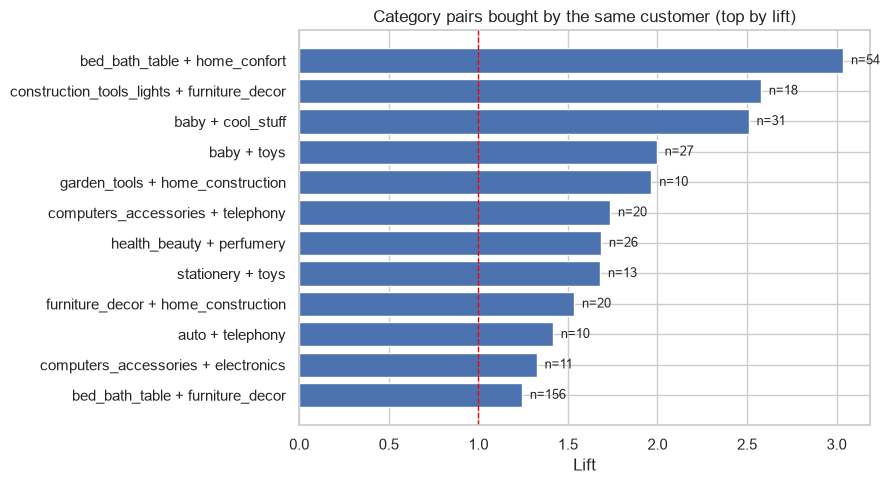

In [24]:
# Top customer-level pairs by lift (one direction per pair)
top = cust_rules.copy()
top["pair"] = top.apply(lambda r: " + ".join(sorted([r.antecedents, r.consequents])), axis=1)
top = top.drop_duplicates("pair").head(12)
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(top["pair"][::-1], top["lift"][::-1])
for y, (l, c) in enumerate(zip(top["lift"][::-1], top["count"][::-1])):
    ax.text(l, y, f"  n={c}", va="center", fontsize=9)
ax.axvline(1, color="red", ls="--", lw=1)
ax.set_xlabel("Lift"); ax.set_title("Category pairs bought by the same customer (top by lift)")
plt.tight_layout(); plt.show()

## 4. Seller segmentation

Sellers are described by sales characteristics (revenue, order volume, average price, category breadth, months active) and service characteristics (review score, customer-late rate, dispatch time and the rate at which the seller hands goods to the carrier after its shipping deadline). Only delivered orders are used, so that every service measure is observed. Sellers with fewer than 5 delivered orders are excluded because rates computed on one or two orders are unstable; they are reported separately.

K-means [MacQueen, 1967] is used as the main method. The number of clusters is chosen with the elbow method and the silhouette coefficient [Rousseeuw, 1987], and the result is checked against Ward hierarchical clustering and against K-means run with different random seeds.

In [25]:
si = items_full[items_full.order_status == "delivered"].merge(
    order_df[["order_id", "is_late", "review_score"]], on="order_id", how="left")
si["dispatch_days"] = (si.order_delivered_carrier_date - si.order_approved_at).dt.total_seconds() / 86400
# Negative values come from the timestamp errors found in 1.1; they are set to 0
si["dispatch_days"] = si["dispatch_days"].clip(lower=0)
si["dispatch_late"] = (si.order_delivered_carrier_date > si.shipping_limit_date).astype(float)
si.loc[si.order_delivered_carrier_date.isna(), "dispatch_late"] = np.nan

seller_df = si.groupby("seller_id").agg(
    revenue=("price", "sum"),
    n_orders=("order_id", "nunique"),
    avg_price=("price", "mean"),
    n_categories=("category", "nunique"),
    first_sale=("order_purchase_timestamp", "min"),
    last_sale=("order_purchase_timestamp", "max"),
    freight_ratio=("freight_value", lambda s: s.sum()),
    review_score=("review_score", "mean"),
    late_rate=("is_late", "mean"),
    dispatch_days=("dispatch_days", "median"),
    dispatch_late_rate=("dispatch_late", "mean"),
)
seller_df["freight_ratio"] = seller_df["freight_ratio"] / seller_df["revenue"]
seller_df["months_active"] = ((seller_df.last_sale - seller_df.first_sale).dt.days / 30.44).clip(lower=1)
seller_df = seller_df.drop(columns=["first_sale", "last_sale"])
print("Sellers with delivered orders:", len(seller_df))
print(seller_df.n_orders.describe(percentiles=[.25, .5, .75, .9, .99]).round(1))

Sellers with delivered orders: 2970
count    2970.0
mean       32.9
std       105.4
min         1.0
25%         2.0
50%         7.0
75%        22.0
90%        73.0
99%       400.5
max      1819.0
Name: n_orders, dtype: float64


In [26]:
MIN_ORDERS = 5
small = seller_df[seller_df.n_orders < MIN_ORDERS]
seg = seller_df[seller_df.n_orders >= MIN_ORDERS].dropna().copy()
print(f"Sellers clustered: {len(seg):,} | excluded (<{MIN_ORDERS} orders): {len(small):,}")
print(f"Share of revenue covered by clustered sellers: {seg.revenue.sum() / seller_df.revenue.sum():.1%}")

features = ["revenue", "n_orders", "avg_price", "n_categories", "months_active",
            "freight_ratio", "review_score", "late_rate", "dispatch_days", "dispatch_late_rate"]
# Volume and price variables are heavily right-skewed, so they are log-transformed before scaling
log_cols = ["revenue", "n_orders", "avg_price", "n_categories", "dispatch_days"]
X_seg = seg[features].copy()
X_seg[log_cols] = np.log1p(X_seg[log_cols])

from sklearn.preprocessing import StandardScaler
X_scaled = StandardScaler().fit_transform(X_seg)
seg[features].skew().round(2).rename("skew before log")

Sellers clustered: 1,766 | excluded (<5 orders): 1,204
Share of revenue covered by clustered sellers: 96.0%


revenue               7.04
n_orders              7.51
avg_price             5.25
n_categories          3.12
months_active         0.51
freight_ratio         1.98
review_score         -1.11
late_rate             2.29
dispatch_days         3.93
dispatch_late_rate    2.41
Name: skew before log, dtype: Float64

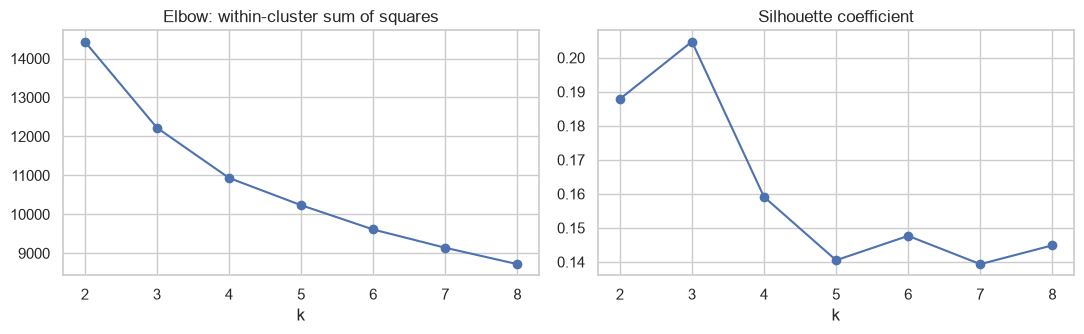

,k,inertia,silhouette
0,2,14434.140,0.188
1,3,12221.928,0.205
2,4,10933.092,0.159
3,5,10233.776,0.140
4,6,9609.776,0.148
5,7,9140.341,0.139
6,8,8719.603,0.145


In [27]:
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score

ks = range(2, 9)
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit(X_scaled)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(X_scaled, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(ks, inertia, marker="o"); axes[0].set_title("Elbow: within-cluster sum of squares"); axes[0].set_xlabel("k")
axes[1].plot(ks, sil, marker="o"); axes[1].set_title("Silhouette coefficient"); axes[1].set_xlabel("k")
plt.tight_layout(); plt.show()
pd.DataFrame({"k": list(ks), "inertia": inertia, "silhouette": sil}).round(3)

In [28]:
K = 4  # chosen from the elbow and silhouette results above (see report for justification)
km = KMeans(n_clusters=K, n_init=20, random_state=RANDOM_STATE).fit(X_scaled)
seg["cluster"] = km.labels_

# Robustness: agreement with other seeds and with Ward hierarchical clustering
seed_ari = [adjusted_rand_score(km.labels_, KMeans(n_clusters=K, n_init=20, random_state=s).fit(X_scaled).labels_)
            for s in [1, 7, 21, 99]]
ward = AgglomerativeClustering(n_clusters=K, linkage="ward").fit(X_scaled)
print("ARI across random seeds:", np.round(seed_ari, 3))
print("ARI K-means vs Ward:", round(adjusted_rand_score(km.labels_, ward.labels_), 3))
print("Silhouette K-means:", round(silhouette_score(X_scaled, km.labels_), 3),
      "| Ward:", round(silhouette_score(X_scaled, ward.labels_), 3))

ARI across random seeds: [1. 1. 1. 1.]
ARI K-means vs Ward: 0.326
Silhouette K-means: 0.159 | Ward: 0.092


In [29]:
# Cluster profiles (medians are used because the variables are skewed)
profile = seg.groupby("cluster")[features].median()
profile.insert(0, "sellers", seg.groupby("cluster").size())
profile.insert(1, "revenue_share", (seg.groupby("cluster").revenue.sum() / seg.revenue.sum()).round(3))
profile.round(3)

,sellers,revenue_share,revenue,n_orders,avg_price,n_categories,months_active,freight_ratio,review_score,late_rate,dispatch_days,dispatch_late_rate
cluster,,,,,,,,,,,,
0,458,0.689,9047.025,89.0,95.848,4.0,15.670,0.217,4.140,0.051,1.605,0.051
1,194,0.060,1897.525,13.0,104.279,2.0,7.917,0.205,3.698,0.143,5.317,0.400
2,502,0.031,618.160,9.0,52.087,2.0,4.468,0.325,4.333,0.0,1.345,0.000
3,612,0.221,2711.980,13.0,160.273,2.0,6.636,0.132,4.315,0.028,1.371,0.000


In [30]:
# Sensitivity: the silhouette peaks at k = 3. Cross-tabulating k = 3 against k = 4 shows whether
# k = 4 is a refinement (one k = 3 group split in two) or a different structure.
km3 = KMeans(n_clusters=3, n_init=20, random_state=RANDOM_STATE).fit(X_scaled)
pd.crosstab(seg["cluster"], km3.labels_, rownames=["k=4 cluster"], colnames=["k=3 cluster"])

k=3 cluster,0,1,2
k=4 cluster,,,
0,2,1,455
1,0,194,0
2,480,15,7
3,427,24,161


In [31]:
# Segment names assigned from the profiles above
segment_names = {0: "Established core", 1: "Service at risk",
                 2: "Small low-ticket, freight-heavy", 3: "Small high-ticket, reliable"}
seg["segment"] = seg["cluster"].map(segment_names)
seg.groupby("segment")[["revenue", "late_rate", "dispatch_late_rate", "review_score"]].agg(["median", "mean"]).round(3)

revenue            late_rate         \
                                   median       mean    median   mean   
segment                                                                 
Established core                 9047.025  19084.855     0.051   0.06   
Service at risk                  1897.525   3913.714     0.143  0.166   
Small high-ticket, reliable      2711.980   4581.564     0.028  0.053   
Small low-ticket, freight-heavy   618.160    779.615       0.0  0.042   

                                dispatch_late_rate        review_score         
                                            median   mean       median   mean  
segment                                                                        
Established core                             0.051  0.080        4.140  4.118  
Service at risk                              0.400  0.418        3.698  3.595  
Small high-ticket, reliable                  0.000  0.054        4.315  4.268  
Small low-ticket, freight-heavy              0.000  0.052        4.333  4.247

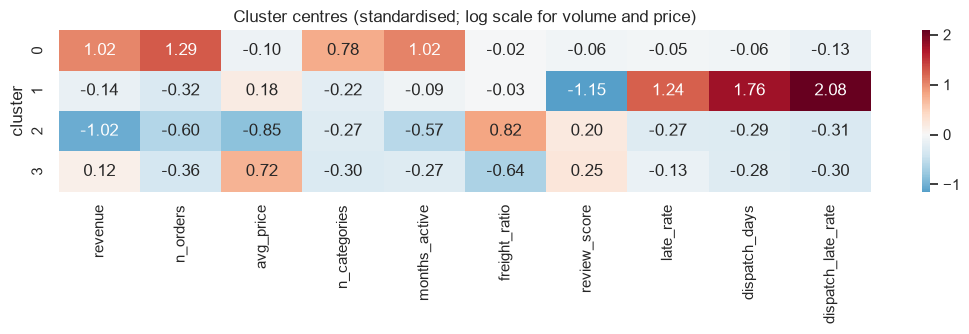

In [32]:
# Standardised cluster centres: how far each segment sits from the average seller on each feature
centres = pd.DataFrame(km.cluster_centers_, columns=features)
fig, ax = plt.subplots(figsize=(11, 3.5))
sns.heatmap(centres, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax)
ax.set_ylabel("cluster"); ax.set_title("Cluster centres (standardised; log scale for volume and price)")
plt.tight_layout(); plt.show()

In [33]:
# Small sellers (excluded from clustering) for comparison
small[features].median().round(3).rename(f"median, sellers with <{MIN_ORDERS} orders")

revenue               179.9
n_orders                2.0
avg_price              90.0
n_categories            1.0
months_active           1.0
freight_ratio         0.206
review_score            4.5
late_rate               0.0
dispatch_days         2.112
dispatch_late_rate      0.0
Name: median, sellers with <5 orders, dtype: Float64

## 5. Unusual orders for operational review

Two approaches are combined. Rule-based integrity checks flag orders whose records are logically impossible or inconsistent, for example a payment that does not match the order value; these need review whatever a model says. Unsupervised anomaly detection then ranks delivered orders by how unusual their combination of value, freight, size, payment, distance and timing is. Isolation Forest [Liu et al., 2008] isolates points with random splits, so anomalies need fewer splits; Local Outlier Factor (LOF) [Breunig et al., 2000] compares each point's local density with that of its neighbours. The two methods define "unusual" differently, so orders flagged by both are treated as the highest priority.

There are no labels, so the flags are validated indirectly. If they are operationally meaningful, flagged orders should have worse review scores, and review scores were not used as inputs. Late rates are also compared, but only as a partial check, because delay days is one of the inputs.

In [34]:
# 5.1 Rule-based integrity flags (all orders)
rules_df = order_df.copy()
rules_df["payment_gap"] = (rules_df.payment_value - (rules_df.total_price + rules_df.total_freight)).abs()
flags = pd.DataFrame(index=rules_df.index)
flags["carrier_before_purchase"] = rules_df.order_delivered_carrier_date < rules_df.order_purchase_timestamp
flags["delivered_before_carrier"] = rules_df.order_delivered_customer_date < rules_df.order_delivered_carrier_date
flags["delivered_status_no_date"] = (rules_df.order_status == "delivered") & rules_df.order_delivered_customer_date.isna()
flags["no_items"] = rules_df.n_items.isna()
flags["no_payment"] = rules_df.payment_value.isna()
flags["payment_mismatch_gt_1BRL"] = rules_df.payment_gap > 1
flags["delay_over_30_days"] = rules_df.delay_days > 30
rules_df["n_flags"] = flags.sum(axis=1)
flags.sum().rename("orders flagged").to_frame()

,orders flagged
carrier_before_purchase,166
delivered_before_carrier,23
delivered_status_no_date,8
no_items,775
no_payment,1
payment_mismatch_gt_1BRL,249
delay_over_30_days,345


In [35]:
# 5.2 Model-based anomaly detection on delivered orders
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor

an = delivered.copy()
an["payment_gap"] = (an.payment_value - (an.total_price + an.total_freight)).abs()
an_features = ["total_price", "total_freight", "freight_ratio", "n_items", "n_sellers",
               "payment_installments", "payment_gap", "distance_km", "approval_hours",
               "delivery_days", "delay_days", "total_weight_g"]
an = an.dropna(subset=an_features)
Xa = an[an_features].copy()
skewed = ["total_price", "total_freight", "freight_ratio", "payment_gap", "distance_km",
          "approval_hours", "delivery_days", "total_weight_g"]
Xa[skewed] = np.log1p(Xa[skewed].clip(lower=0))
Xa_s = StandardScaler().fit_transform(Xa)
print("Orders scored:", len(an))

CONTAM = 0.01  # review capacity assumption: about 1% of orders
iso = IsolationForest(n_estimators=300, contamination=CONTAM, random_state=RANDOM_STATE).fit(Xa_s)
an["iso_score"] = -iso.score_samples(Xa_s)           # higher = more anomalous
an["iso_flag"] = iso.predict(Xa_s) == -1
lof = LocalOutlierFactor(n_neighbors=35, contamination=CONTAM)
an["lof_flag"] = lof.fit_predict(Xa_s) == -1
an["lof_score"] = -lof.negative_outlier_factor_
an["both_flag"] = an.iso_flag & an.lof_flag
print(an[["iso_flag", "lof_flag", "both_flag"]].sum())
from scipy.stats import spearmanr
print("Spearman correlation of the two scores:", round(spearmanr(an.iso_score, an.lof_score).statistic, 3))

Orders scored: 95978
iso_flag     960
lof_flag     960
both_flag    117
dtype: int64
Spearman correlation of the two scores: 0.397


In [36]:
# Indirect validation: outcomes NOT used as inputs
def outcome(mask):
    d = an[mask]
    return pd.Series({"orders": len(d), "mean review": d.review_score.mean(),
                      "share 1-star": (d.review_score == 1).mean(), "late rate": d.is_late.mean()})
pd.DataFrame({"all delivered": outcome(an.index == an.index),
              "Isolation Forest": outcome(an.iso_flag),
              "LOF": outcome(an.lof_flag),
              "both methods": outcome(an.both_flag)}).T.round(3)

,orders,mean review,share 1-star,late rate
all delivered,95978.0,4.156,0.097,0.068
Isolation Forest,960.0,3.017,0.341,0.101
LOF,960.0,3.822,0.180,0.120
both methods,117.0,2.798,0.402,0.231


In [37]:
# What makes flagged orders unusual: median feature values, flagged vs all
comp = pd.DataFrame({"all delivered": an[an_features].median(),
                     "IF flagged": an.loc[an.iso_flag, an_features].median(),
                     "LOF flagged": an.loc[an.lof_flag, an_features].median(),
                     "both": an.loc[an.both_flag, an_features].median()})
comp.round(2)

,all delivered,IF flagged,LOF flagged,both
total_price,86.00,256.33,105.00,269.99
total_freight,17.16,70.15,20.48,84.32
freight_ratio,0.22,0.30,0.25,0.33
n_items,1.00,3.00,1.00,3.00
n_sellers,1.00,2.00,1.00,1.00
payment_installments,2.00,5.00,2.00,6.00
payment_gap,0.00,0.00,0.00,0.00
distance_km,433.83,509.61,310.01,527.18
approval_hours,0.34,3.23,0.50,0.94
delivery_days,10.21,10.02,11.21,12.02


In [38]:
# Sensitivity: how the Isolation Forest flag set changes with the contamination (review budget)
base = set(an.index[an.iso_flag])
rows = []
for c in [0.005, 0.01, 0.02, 0.05, 0.10]:
    f = IsolationForest(n_estimators=300, contamination=c, random_state=RANDOM_STATE).fit_predict(Xa_s) == -1
    alt = IsolationForest(n_estimators=300, contamination=c, random_state=7).fit_predict(Xa_s) == -1
    s, s_alt = set(an.index[f]), set(an.index[alt])
    rows.append({"contamination": c, "flagged": len(s),
                 "share of 1% set contained": len(base & s) / len(base),
                 "overlap with other seed (Jaccard)": len(s & s_alt) / len(s | s_alt),
                 "mean review of flagged": an.loc[f, "review_score"].mean(),
                 "1-star share of flagged": (an.loc[f, "review_score"] == 1).mean()})
pd.DataFrame(rows).round(3)

,contamination,flagged,share of 1% set contained,overlap with other seed (Jaccard),mean review of flagged,1-star share of flagged
0,0.005,480,0.5,0.758,2.791,0.388
1,0.010,960,1.0,0.739,3.017,0.341
2,0.020,1920,1.0,0.774,3.049,0.331
3,0.050,4799,1.0,0.788,3.321,0.280
4,0.100,9598,1.0,0.801,3.514,0.239


In [39]:
# Simple baseline: z-score on (log) order value alone, |z| > 3
z = (np.log1p(an.total_price) - np.log1p(an.total_price).mean()) / np.log1p(an.total_price).std()
an["z_flag"] = z.abs() > 3
print("Orders flagged by z-score baseline:", an.z_flag.sum())
print("Overlap with Isolation Forest flags:", (an.z_flag & an.iso_flag).sum())
pd.DataFrame({"z-score baseline": outcome(an.z_flag), "Isolation Forest": outcome(an.iso_flag),
              "both models": outcome(an.both_flag)}).T.round(3)

Orders flagged by z-score baseline: 494
Overlap with Isolation Forest flags: 62


,orders,mean review,share 1-star,late rate
z-score baseline,494.0,3.879,0.180,0.103
Isolation Forest,960.0,3.017,0.341,0.101
both models,117.0,2.798,0.402,0.231


In [40]:
# Manual inspection: the 20 highest-scoring orders flagged by both models, with the reasons they stand out
p99 = an[["total_price", "total_freight", "total_weight_g", "distance_km"]].quantile(0.99)
def reasons(r):
    out = []
    if r.freight_ratio > 1 or r.total_freight > p99.total_freight: out.append("extreme freight")
    if r.n_items >= 5: out.append("bulk multi-item")
    if r.payment_gap > 1: out.append("payment mismatch")
    if r.total_weight_g > p99.total_weight_g: out.append("very heavy")
    if r.total_price > p99.total_price: out.append("very high value")
    if r.n_sellers >= 2: out.append("multi-seller")
    if r.delay_days > 30: out.append("severe delay")
    if r.approval_hours > 48: out.append("slow approval")
    return ", ".join(out) if out else "unusual combination"
flagged = an[an.both_flag].sort_values("iso_score", ascending=False).copy()
flagged["reasons"] = flagged.apply(reasons, axis=1)
cat_counts = flagged["reasons"].str.split(", ").explode().value_counts()
print("Reasons across all", len(flagged), "orders flagged by both models:")
print(cat_counts.to_string())
flagged[["order_id", "total_price", "total_freight", "n_items", "payment_gap", "total_weight_g", "review_score", "reasons"]].head(20).round(1)

Reasons across all 117 orders flagged by both models:
reasons
extreme freight        65
multi-seller           48
bulk multi-item        45
very heavy             28
very high value        26
payment mismatch       12
severe delay           12
slow approval          11
unusual combination     3


,order_id,total_price,total_freight,n_items,payment_gap,total_weight_g,review_score,reasons
48686,6e5fe7366a2e1bfbf3257dba0af1267f,179.2,108.7,6.0,119.0,10200.0,1.0,"extreme freight, bulk multi-item, payment mism..."
98927,62073ec6b54b8e6322037fc0f3591ad3,859.7,456.5,7.0,0.0,84199.0,2.0,"extreme freight, bulk multi-item, very heavy, ..."
83194,9bdf94af058f959fbc09c3ea1eb32465,172.1,55.5,7.0,0.0,2650.0,1.0,"bulk multi-item, multi-seller"
9200,0c82a229fc22597c2361656cba8d3230,497.1,69.0,7.0,0.0,6150.0,5.0,"bulk multi-item, multi-seller"
52985,70b7e94ea46d3e8b5bc12a50186edaf0,167.9,45.3,3.0,61.7,513.0,1.0,"payment mismatch, multi-seller"
25646,e37f11cae9985ca58f0b56f268720537,106.6,114.2,7.0,0.0,7800.0,5.0,"extreme freight, bulk multi-item, multi-seller"
16335,71dab1155600756af6de79de92e712e3,1361.9,626.6,11.0,0.0,86585.0,3.0,"extreme freight, bulk multi-item, very heavy, ..."
84613,674eb13687ba86abeaee12ece9ce0309,127.0,21.0,6.0,0.0,1320.0,5.0,"bulk multi-item, multi-seller"
20074,cf4659487be50c0c317cff3564c4a840,1050.0,1795.0,6.0,0.0,112200.0,5.0,"extreme freight, bulk multi-item, very heavy, ..."
59842,ca3625898fbd48669d50701aba51cd5f,1138.3,19.0,10.0,0.0,29900.0,3.0,"bulk multi-item, very heavy, very high value, ..."


## 6. Predicting late delivery and delivery time

Targets: `is_late` (delivered after Olist's estimated date) for classification, and `delivery_days` (purchase to delivery) for regression.

Leakage control: only information available at the moment of purchase is used, namely order contents, price, freight, weight, payment terms, customer and seller location, distance, purchase calendar and Olist's own estimated delivery time. Carrier and delivery timestamps, approval time and review scores are excluded because they are only known later [Kaufman et al., 2012].

Validation: orders are split by purchase date, so the models are trained on the past and tested on the future, as they would be used in practice. The sparse months of 2016 are excluded. Training covers January 2017 to March 2018 and testing April to August 2018; the last three months of the training period are held out as a validation set for choosing the classification threshold.

Imbalance: only about 7% of orders are late, so accuracy is misleading. Precision-recall AUC is the main metric [Saito & Rehmsmeier, 2015], with ROC-AUC, precision, recall and F1 also reported, and every model is compared with simple baselines.

In [41]:
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (roc_auc_score, average_precision_score, precision_score, recall_score,
                             f1_score, mean_absolute_error, mean_squared_error, r2_score)

m = delivered[delivered.order_purchase_timestamp >= "2017-01-01"].copy()
m["purchase_month"] = m.order_purchase_timestamp.dt.month
m["purchase_dow"] = m.order_purchase_timestamp.dt.dayofweek
m["purchase_hour"] = m.order_purchase_timestamp.dt.hour
m["log_volume"] = np.log1p(m.total_volume_cm3)

num_feats = ["estimated_days", "distance_km", "same_state", "total_price", "total_freight", "freight_ratio",
             "n_items", "n_sellers", "total_weight_g", "log_volume", "payment_installments",
             "purchase_month", "purchase_dow", "purchase_hour"]
cat_feats = ["customer_state", "seller_state", "main_category", "payment_type"]
m = m.dropna(subset=num_feats + cat_feats)
for c in cat_feats:
    m[c] = m[c].astype("category")

train = m[m.order_purchase_timestamp < "2018-04-01"]
test = m[m.order_purchase_timestamp >= "2018-04-01"]
fit = train[train.order_purchase_timestamp < "2018-01-01"]    # used to fit when a validation set is needed
val = train[train.order_purchase_timestamp >= "2018-01-01"]
for name, d in [("train", train), ("  fit", fit), ("  validation", val), ("test", test)]:
    print(f"{name:14s} {len(d):6,} orders | late rate {d.is_late.mean():.2%} | median days {d.delivery_days.median():.1f}")

C:\Users\DELL\AppData\Local\Temp\ipykernel_2976\1036984763.py:13: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  m["purchase_dow"] = m.order_purchase_timestamp.dt.dayofweek


train          63,723 orders | late rate 7.97% | median days 11.6
  fit          43,202 orders | late rate 5.64% | median days 11.0
  validation   20,521 orders | late rate 12.86% | median days 13.2
test           32,003 orders | late rate 4.40% | median days 8.1


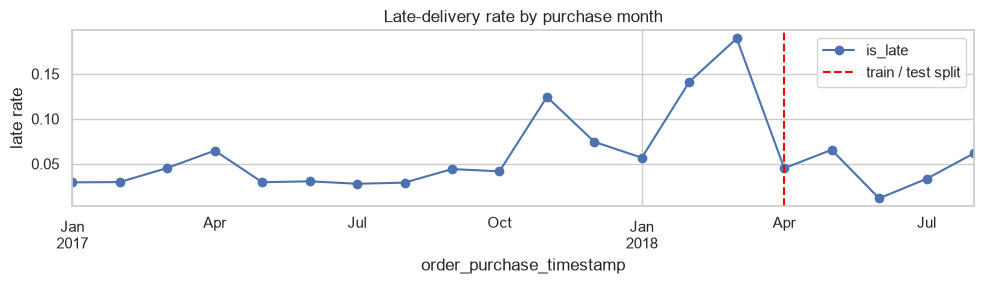

,late_rate,orders
order_purchase_timestamp,,
2017-01-01,0.029,750
2017-02-01,0.03,1653
2017-03-01,0.045,2536
2017-04-01,0.065,2289
2017-05-01,0.029,3527
2017-06-01,0.031,3114
2017-07-01,0.028,3853
2017-08-01,0.029,4170
2017-09-01,0.044,4125


In [42]:
# Late rate by purchase month: checks whether the test period resembles the training period
ax = m.set_index("order_purchase_timestamp").resample("MS").is_late.mean().plot(figsize=(10, 3), marker="o")
ax.axvline(pd.Timestamp("2018-04-01"), color="red", ls="--", label="train / test split")
ax.set_title("Late-delivery rate by purchase month"); ax.set_ylabel("late rate"); ax.legend()
plt.tight_layout(); plt.show()

# The same figures as a table (late rate and number of delivered orders per month)
m.set_index("order_purchase_timestamp").resample("MS").agg(late_rate=("is_late", "mean"), orders=("order_id", "count")).round(3)

### 6.1 Late-delivery classification

In [43]:
X_cols = num_feats + cat_feats
pre = ColumnTransformer([("num", StandardScaler(), num_feats),
                         ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=20), cat_feats)])

def make_logit():
    return make_pipeline(pre, LogisticRegression(max_iter=2000, class_weight="balanced"))

def make_rf_clf():
    return make_pipeline(pre, RandomForestClassifier(n_estimators=200, min_samples_leaf=20, max_features="sqrt",
                         class_weight="balanced_subsample", n_jobs=-1, random_state=RANDOM_STATE))

def make_gb_clf():
    # Histogram-based gradient boosting; pandas 'category' columns are handled natively
    return HistGradientBoostingClassifier(max_iter=400, learning_rate=0.05, max_leaf_nodes=31, min_samples_leaf=50,
                                          categorical_features="from_dtype", early_stopping=False,
                                          random_state=RANDOM_STATE)

y_fit, y_val, y_tr, y_te = (d.is_late.astype(int) for d in (fit, val, train, test))

# Choose each model's threshold on the validation period (max F1), then refit on all training data
def val_threshold(model):
    model.fit(fit[X_cols], y_fit)
    p = model.predict_proba(val[X_cols])[:, 1]
    grid = np.linspace(0.05, 0.95, 91)
    return grid[np.argmax([f1_score(y_val, p >= t, zero_division=0) for t in grid])]

clf_results, test_probs = [], {}
clf_models = {}
for name, factory in [("Logistic regression", make_logit), ("Random forest", make_rf_clf), ("Gradient boosting", make_gb_clf)]:
    t = val_threshold(factory())
    model = factory().fit(train[X_cols], y_tr)
    p = model.predict_proba(test[X_cols])[:, 1]
    test_probs[name] = p
    clf_results.append({"model": name, "threshold": t, "ROC-AUC": roc_auc_score(y_te, p),
                        "PR-AUC": average_precision_score(y_te, p),
                        "precision": precision_score(y_te, p >= t, zero_division=0),
                        "recall": recall_score(y_te, p >= t), "F1": f1_score(y_te, p >= t)})
    clf_models[name] = (model, t)
    if name == "Gradient boosting":
        gb_clf = model

# Baselines: (a) always "on time" (Olist's own estimate implies no order is late);
# (b) a one-feature rule: shorter promised delivery windows are more likely to be missed
prev = y_te.mean()
base_rule = -test.estimated_days.values
clf_results = [
    {"model": "Baseline: always on time", "threshold": np.nan, "ROC-AUC": 0.5, "PR-AUC": prev,
     "precision": 0.0, "recall": 0.0, "F1": 0.0},
    {"model": "Baseline: short estimate = risky", "threshold": np.nan, "ROC-AUC": roc_auc_score(y_te, base_rule),
     "PR-AUC": average_precision_score(y_te, base_rule), "precision": np.nan, "recall": np.nan, "F1": np.nan},
] + clf_results
clf_table = pd.DataFrame(clf_results).set_index("model").round(3)
clf_table

,threshold,ROC-AUC,PR-AUC,precision,recall,F1
model,,,,,,
Baseline: always on time,NaN,0.500,0.044,0.000,0.000,0.000
Baseline: short estimate = risky,NaN,0.631,0.093,NaN,NaN,NaN
Logistic regression,0.36,0.718,0.102,0.057,0.929,0.107
Random forest,0.36,0.692,0.091,0.080,0.525,0.138
Gradient boosting,0.05,0.684,0.089,0.076,0.557,0.134


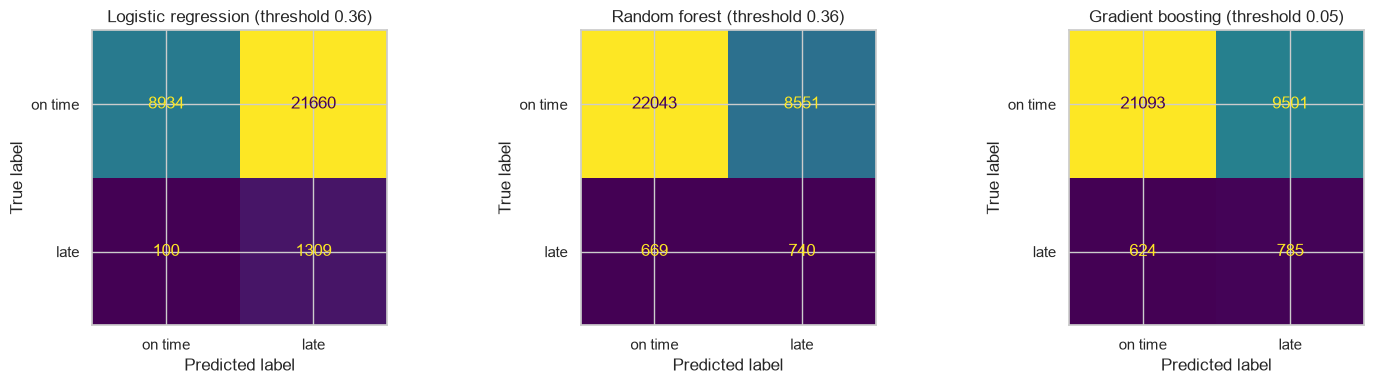

,PR-AUC train,PR-AUC test,ROC-AUC train,ROC-AUC test
model,,,,
Logistic regression,0.195,0.102,0.718,0.718
Random forest,0.453,0.091,0.897,0.692
Gradient boosting,0.614,0.089,0.929,0.684


In [44]:
# Confusion matrices on the test period at each model's validation-chosen threshold
from sklearn.metrics import ConfusionMatrixDisplay
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, (model, t)) in zip(axes, clf_models.items()):
    ConfusionMatrixDisplay.from_predictions(y_te, (test_probs[name] >= t).astype(int), ax=ax, colorbar=False,
                                            display_labels=["on time", "late"])
    ax.set_title(f"{name} (threshold {t:.2f})")
plt.tight_layout(); plt.show()

# Overfitting check: training versus test ranking performance
pd.DataFrame([{"model": n, "PR-AUC train": average_precision_score(y_tr, m.predict_proba(train[X_cols])[:, 1]),
               "PR-AUC test": average_precision_score(y_te, test_probs[n]),
               "ROC-AUC train": roc_auc_score(y_tr, m.predict_proba(train[X_cols])[:, 1]),
               "ROC-AUC test": roc_auc_score(y_te, test_probs[n])} for n, (m, t) in clf_models.items()]).set_index("model").round(3)

In [45]:
# Threshold sensitivity for gradient boosting on the test period
p = test_probs["Gradient boosting"]
pd.DataFrame([{"threshold": t, "flagged share": (p >= t).mean(),
               "precision": precision_score(y_te, p >= t, zero_division=0),
               "recall": recall_score(y_te, p >= t), "F1": f1_score(y_te, p >= t)}
              for t in [0.1, 0.2, 0.3, 0.4, 0.5]]).round(3)

,threshold,flagged share,precision,recall,F1
0,0.1,0.109,0.111,0.274,0.158
1,0.2,0.022,0.130,0.064,0.086
2,0.3,0.007,0.154,0.024,0.042
3,0.4,0.002,0.121,0.006,0.011
4,0.5,0.001,0.150,0.002,0.004


In [46]:
# Stability: expanding-window cross-validation within the training period (PR-AUC by fold)
cv_rows = []
cuts = ["2017-07-01", "2017-10-01", "2018-01-01", "2018-04-01"]
for start, end in zip(cuts[:-1], cuts[1:]):
    tr = train[train.order_purchase_timestamp < start]
    va = train[(train.order_purchase_timestamp >= start) & (train.order_purchase_timestamp < end)]
    row = {"validation fold": f"{start[:7]} to {end[:7]}", "late rate": va.is_late.mean()}
    for name, factory in [("Logistic regression", make_logit), ("Gradient boosting", make_gb_clf)]:
        pr = factory().fit(tr[X_cols], tr.is_late.astype(int)).predict_proba(va[X_cols])[:, 1]
        row[f"PR-AUC {name}"] = average_precision_score(va.is_late.astype(int), pr)
    cv_rows.append(row)
pd.DataFrame(cv_rows).round(3)

,validation fold,late rate,PR-AUC Logistic regression,PR-AUC Gradient boosting
0,2017-07 to 2017-10,0.034,0.074,0.055
1,2017-10 to 2018-01,0.087,0.121,0.125
2,2018-01 to 2018-04,0.129,0.275,0.190


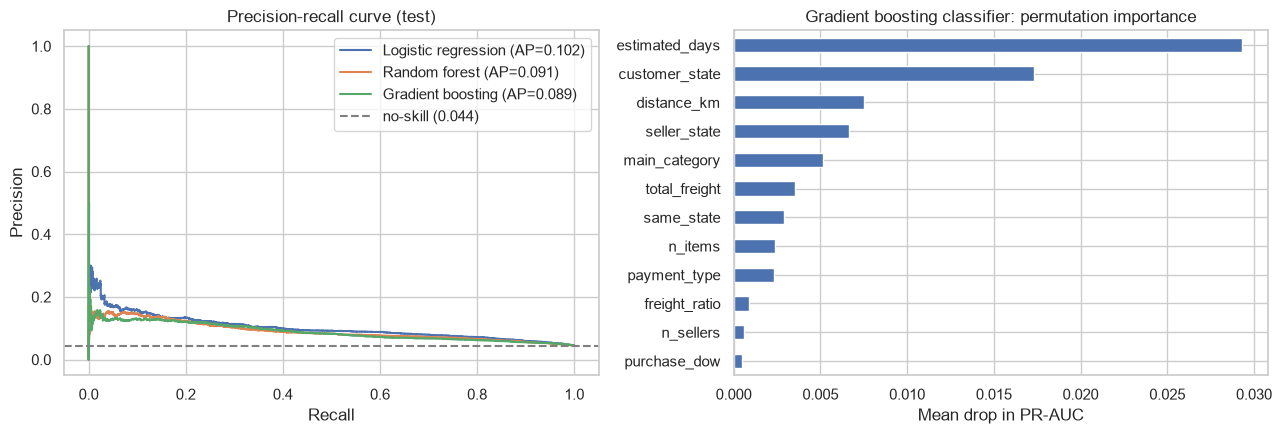

In [47]:
from sklearn.metrics import precision_recall_curve
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for name, p in test_probs.items():
    pr, rc, _ = precision_recall_curve(y_te, p)
    axes[0].plot(rc, pr, label=f"{name} (AP={average_precision_score(y_te, p):.3f})")
axes[0].axhline(prev, color="grey", ls="--", label=f"no-skill ({prev:.3f})")
axes[0].set_xlabel("Recall"); axes[0].set_ylabel("Precision"); axes[0].set_title("Precision-recall curve (test)"); axes[0].legend()
# Permutation importance: drop in test PR-AUC when one feature is shuffled (sample of 10,000 test orders)
samp = test.sample(10000, random_state=RANDOM_STATE)
pi = permutation_importance(gb_clf, samp[X_cols], samp.is_late.astype(int), scoring="average_precision",
                            n_repeats=5, random_state=RANDOM_STATE)
imp = pd.Series(pi.importances_mean, index=X_cols).sort_values()
imp.tail(12).plot.barh(ax=axes[1]); axes[1].set_title("Gradient boosting classifier: permutation importance")
axes[1].set_xlabel("Mean drop in PR-AUC")
plt.tight_layout(); plt.show()

### 6.2 Delivery-time regression

In [48]:
def make_gb_reg():
    return HistGradientBoostingRegressor(max_iter=600, learning_rate=0.05, max_leaf_nodes=31, min_samples_leaf=50,
                                         categorical_features="from_dtype", early_stopping=False,
                                         random_state=RANDOM_STATE)

yd_tr, yd_te = train.delivery_days, test.delivery_days
preds = {
    "Baseline: training median": np.full(len(test), yd_tr.median()),
    "Baseline: Olist estimate": test.estimated_days.values,
    "Linear regression": make_pipeline(pre, LinearRegression()).fit(train[X_cols], yd_tr).predict(test[X_cols]),
}
rf_reg = make_pipeline(pre, RandomForestRegressor(n_estimators=200, min_samples_leaf=20, max_features="sqrt",
                                                   n_jobs=-1, random_state=RANDOM_STATE)).fit(train[X_cols], yd_tr)
preds["Random forest"] = rf_reg.predict(test[X_cols])
gb_reg = make_gb_reg().fit(train[X_cols], yd_tr)
preds["Gradient boosting"] = gb_reg.predict(test[X_cols])
# Variant trained on log(days): reduces the pull of the long right tail of delivery times
gb_log = make_gb_reg().fit(train[X_cols], np.log1p(yd_tr))
preds["Gradient boosting (log target)"] = np.expm1(gb_log.predict(test[X_cols]))

reg_table = pd.DataFrame([{"model": k, "MAE": mean_absolute_error(yd_te, v),
                           "RMSE": np.sqrt(mean_squared_error(yd_te, v)), "R2": r2_score(yd_te, v),
                           "mean error (bias)": np.mean(v - yd_te)} for k, v in preds.items()]).set_index("model")

# Overfitting check: training versus test MAE
reg_fitted = {"Linear regression": make_pipeline(pre, LinearRegression()).fit(train[X_cols], yd_tr),
              "Random forest": rf_reg, "Gradient boosting": gb_reg}
fit_check = pd.DataFrame([{"model": n, "MAE train": mean_absolute_error(yd_tr, m.predict(train[X_cols])),
                           "MAE test": mean_absolute_error(yd_te, m.predict(test[X_cols]))} for n, m in reg_fitted.items()]
                         + [{"model": "Gradient boosting (log target)", "MAE train": mean_absolute_error(yd_tr, np.expm1(gb_log.predict(train[X_cols]))),
                             "MAE test": mean_absolute_error(yd_te, preds["Gradient boosting (log target)"])}]).set_index("model")
display(reg_table.round(2)); fit_check.round(2)

,MAE,RMSE,R2,mean error (bias)
model,,,,
Baseline: training median,5.53,7.32,-0.06,1.79
Baseline: Olist estimate,12.78,15.22,-3.60,12.03
Linear regression,5.26,6.88,0.06,3.15
Random forest,4.90,6.43,0.18,2.62
Gradient boosting,4.45,6.21,0.23,1.78
Gradient boosting (log target),3.94,5.89,0.31,0.66


,MAE train,MAE test
model,,
Linear regression,5.59,5.26
Random forest,5.19,4.90
Gradient boosting,4.63,4.45
Gradient boosting (log target),4.49,3.94


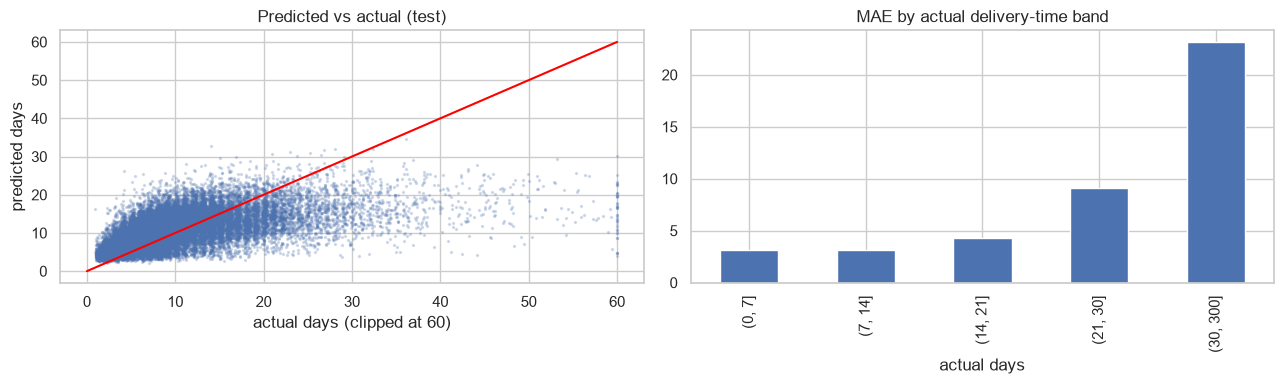

estimated_days    0.0290
same_state        0.0275
distance_km       0.0243
purchase_dow      0.0055
customer_state    0.0054
purchase_month    0.0048
total_freight     0.0043
payment_type      0.0041
Name: mean increase in MAE (log days), dtype: float64

In [49]:
# Diagnostics: residuals and error by actual delivery time
best = preds["Gradient boosting (log target)"]
res = best - yd_te.values
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].scatter(yd_te.clip(upper=60), best, s=2, alpha=0.2)
axes[0].plot([0, 60], [0, 60], color="red"); axes[0].set_xlabel("actual days (clipped at 60)"); axes[0].set_ylabel("predicted days")
axes[0].set_title("Predicted vs actual (test)")
bins = pd.cut(yd_te, [0, 7, 14, 21, 30, 300])
pd.Series(np.abs(res), index=yd_te.index).groupby(bins, observed=True).mean().plot.bar(ax=axes[1])
axes[1].set_title("MAE by actual delivery-time band"); axes[1].set_xlabel("actual days")
plt.tight_layout(); plt.show()
# Permutation importance for the log-target model: increase in test MAE (days) when a feature is shuffled
pi_r = permutation_importance(gb_log, samp[X_cols], np.log1p(samp.delivery_days), scoring="neg_mean_absolute_error",
                              n_repeats=5, random_state=RANDOM_STATE)
imp_r = pd.Series(pi_r.importances_mean, index=X_cols).sort_values(ascending=False)
imp_r.head(8).round(4).rename("mean increase in MAE (log days)")

### 6.3 Using the delivery-time model to flag late-risk orders

An order is late when its actual delivery time exceeds the promised time, so the regression model offers a second route to the classification problem. The predicted slack, defined as predicted delivery days minus Olist's estimated days, ranks orders by how close they are expected to come to their promised date, and this score is compared with the classifiers. The late rate shifts strongly between periods (see the monthly plot above), so the scores are also compared at a fixed review budget of the riskiest 10% of orders, which does not depend on a threshold chosen in a different period.

In [50]:
scores = {"Baseline: short estimate = risky": -test.estimated_days.values,
          "Logistic regression": test_probs["Logistic regression"],
          "Random forest classifier": test_probs["Random forest"],
          "Gradient boosting classifier": test_probs["Gradient boosting"],
          "Predicted slack (gradient boosting, log target)": preds["Gradient boosting (log target)"] - test.estimated_days.values}
rows = []
for name, s in scores.items():
    top = s >= np.quantile(s, 0.90)
    rows.append({"score": name, "ROC-AUC": roc_auc_score(y_te, s), "PR-AUC": average_precision_score(y_te, s),
                 "precision @ top 10%": y_te[top].mean(), "recall @ top 10%": y_te[top].sum() / y_te.sum()})
final_clf = pd.DataFrame(rows).set_index("score")
final_clf["PR-AUC / no-skill"] = final_clf["PR-AUC"] / prev
final_clf.round(3)

,ROC-AUC,PR-AUC,precision @ top 10%,recall @ top 10%,PR-AUC / no-skill
score,,,,,
Baseline: short estimate = risky,0.631,0.093,0.110,0.250,2.118
Logistic regression,0.718,0.102,0.118,0.268,2.312
Random forest classifier,0.692,0.091,0.109,0.248,2.058
Gradient boosting classifier,0.684,0.089,0.114,0.259,2.011
"Predicted slack (gradient boosting, log target)",0.717,0.120,0.135,0.307,2.720
